# TMDB Top Rated Movies — Web Scraping & EDA

In [1]:
import requests
import re
import time
import random
import pandas as pd
import numpy as np
from bs4 import BeautifulSoup

TMDB closes the connection when a plain Python request visits it, so we open the pages in a real Chrome browser with Selenium (run `pip install selenium` once; Chrome must be installed).

In [2]:
from selenium import webdriver
from selenium.webdriver.support.ui import WebDriverWait

options = webdriver.ChromeOptions()
options.page_load_strategy = "eager"                          # don't wait for every image and script
options.add_argument("--blink-settings=imagesEnabled=false")  # no images = much faster pages
driver = webdriver.Chrome(options=options)      # a real Chrome window opens, TMDB accepts it like a normal visitor

def fetch(url, wait=1):
    driver.get(url)
    time.sleep(random.uniform(wait, wait + 1))      # let the page finish loading
    return driver.page_source

In [3]:
url = 'https://www.themoviedb.org/movie/top-rated'
html_data = fetch(url)

In [4]:
len(html_data)

651422

In [5]:
# quick check: a long text and a movie page title means we really got the page
print(len(html_data))
print(BeautifulSoup(html_data, "html.parser").title)

651422
<title>Top Rated — The Movie Database (TMDB)</title>


In [6]:
soup = BeautifulSoup(html_data, "html.parser")

In [7]:
# ONLY if the page above is empty or a block page:
# open the page in your browser, press Ctrl+S, save it as tmdb_top.html next to this notebook, then run:
# soup = BeautifulSoup(open("tmdb_top.html", encoding="utf-8").read(), "html.parser")

In [8]:
DATE_RE = r"(?:[A-Z][a-z]+\.?\s+\d{1,2},\s+\d{4}|\d{1,2}\s+[A-Z][a-z]+\s+\d{4})"

def movie_id(a):
    m = re.match(r"/movie/(\d+)", a.get("href", ""))
    return m.group(1) if m else None

def find_cards(soup):
    # each movie card is a box with a data-object-id attribute (that is how TMDB marks a movie)
    cards = [c for c in soup.select("div[data-object-id]") if c.select_one("a[href^='/movie/']")]
    if cards:
        return cards
    # backup: if TMDB renames things again, find the box that holds exactly ONE movie and a release date
    cards, seen = [], set()
    for a in soup.select("a[href^='/movie/']"):
        mid = movie_id(a)
        if not mid or mid in seen:
            continue
        best, node = None, a
        for _ in range(8):
            node = node.parent
            if node is None:
                break
            ids = {movie_id(x) for x in node.select("a[href^='/movie/']")} - {None}
            if len(ids) > 1:
                break
            if re.search(DATE_RE, node.get_text(" ")):
                best = node
        if best is not None:
            seen.add(mid)
            cards.append(best)
    return cards

cards = find_cards(soup)
len(cards)

20

In [9]:
# if the number above is 0, this shows what the page contains (send me this output)
print("movie links:", len(soup.select("a[href^='/movie/']")), "| scores:", len(soup.select("[data-percent]")))
print([a.get("title") or a.get_text(strip=True) for a in soup.select("a[href^='/movie/']")][:8])

movie links: 54 | scores: 0
['Now Playing', 'Upcoming', 'Top Rated', 'Now Playing', 'Upcoming', 'Top Rated', 'List', 'Calendar']


In [10]:
cards[0] if len(cards) > 0 else "no cards found"

<div class="w-full overflow-hidden rounded-xl border border-gray-200 bg-white shadow-sm transition-colors hover:border-gray-300" data-object-id="68e9758d4265dc96935f6ae5" id="68e9758d4265dc96935f6ae5"><div class="flex flex-wrap content-start items-start"><div class="relative w-full"><a class="flex w-full" href="/movie/1560520-batman-knightfall-part-1-knightfall"><div class="image no_image_holder glyphicons picture aspect-poster flex overflow-hidden bg-light-grey! grey rounded-none!"><img alt="Batman: Knightfall Part 1: Knightfall" class="poster w-full block" decoding="async" fetchpriority="low" loading="lazy" src="https://media.themoviedb.org/t/p/w220_and_h330_face/360qdtu2hLnqMu8SVHMywn420w1.jpg" srcset="https://media.themoviedb.org/t/p/w220_and_h330_face/360qdtu2hLnqMu8SVHMywn420w1.jpg 1x, https://media.themoviedb.org/t/p/w440_and_h660_face/360qdtu2hLnqMu8SVHMywn420w1.jpg 2x"/></div></a><div class="options w-[26px] h-[26px] absolute top-2 right-2" data-id="1560520" data-media-type="m

In [14]:
Movie_name = []

for i in cards:
    title = i.select_one("h2")
    if title:
        name = title.get_text(" ", strip=True)
        if name:
            Movie_name.append(name)

Movie_name

['Batman: Knightfall Part 1: Knightfall',
 'Avatar Aang: The Last Airbender',
 'Swapped',
 'Accidental Partners',
 'Demon Slayer: Kimetsu no Yaiba Infinity Castle',
 'Facing El Chapo',
 'The Shawshank Redemption',
 'The Godfather',
 'Project Hail Mary',
 'Michael',
 'Young Hearts',
 '12 Angry Men',
 'The Godfather Part II',
 "Schindler's List",
 'My Dearest Assassin',
 'The Dark Knight',
 'Chainsaw Man - The Movie: Reze Arc',
 'Spirited Away',
 'The Green Mile',
 'The Lord of the Rings: The Return of the King']

In [15]:
def get_text(card, selector):
    tag = card.select_one(selector)
    return tag.get_text(strip=True) if tag else None

def get_title(card):
    h2 = card.select_one("h2")
    if h2 and h2.get_text(strip=True):
        return h2.get_text(" ", strip=True)
    for a in card.select("a[href^='/movie/']"):
        name = a.get("title") or a.get_text(strip=True)
        if name:
            return name
    return None

def get_link(card):
    tag = card.select_one("a[href^='/movie/']")
    if tag and tag.get("href"):
        return "https://www.themoviedb.org" + tag["href"].split("?")[0]
    return None

def get_date(card):
    # the release date is written like "June 23, 2026"
    tag = card.select_one("span.release_date")
    if tag and tag.get_text(strip=True):
        return tag.get_text(strip=True)
    m = re.search(DATE_RE, card.get_text(" "))
    return m.group(0) if m else None

def get_score(card):
    # the list page may not show the score, then it is taken from the movie page later
    tag = card.select_one("[data-percent]")
    return tag.get("data-percent") if tag else None

def scrape_card(card):
    title = get_title(card)
    date = get_date(card)
    score = get_score(card)
    paras = [p.get_text(" ", strip=True) for p in card.select("p")]
    overview = max(paras, key=len) if paras else None
    link = get_link(card)
    return title, date, score, overview, link

In [16]:
Title = []
Release_Date = []
Rating = []
Overview = []
Link = []

for card in cards:
    t, d, s, o, l = scrape_card(card)
    if not t:
        continue
    Title.append(t)
    Release_Date.append(d)
    Rating.append(s)
    Overview.append(o)
    Link.append(l)

In [17]:
print(len(Title))
print(len(Release_Date))
print(len(Rating))
print(len(Overview))
print(len(Link))

20
20
20
20
20


In [18]:
min_len = min(len(Title),
len(Release_Date),
len(Rating),
len(Overview),
len(Link))

In [19]:
min_len

20

### Scraping many pages (up to 25 pages, 20 movies each) to get 500 records

In [20]:
Title = []
Release_Date = []
Rating = []
Overview = []
Link = []
seen = set()

for page in range(1, 26):
    url = f"https://www.themoviedb.org/movie/top-rated?page={page}"
    html = fetch(url)
    soup = BeautifulSoup(html, "html.parser")
    cards = find_cards(soup)
    if len(cards) == 0:
        break
    before = len(Title)
    for card in cards:
        t, d, s, o, l = scrape_card(card)
        if not t or not l or l in seen:
            continue
        seen.add(l)
        Title.append(t)
        Release_Date.append(d)
        Rating.append(s)
        Overview.append(o)
        Link.append(l)
    if len(Title) == before:
        print("No new movies on page", page, "- stopping")
        break

print("pages scraped, total movies:", len(Title))

pages scraped, total movies: 500


In [21]:
print(len(Title))
print(len(Release_Date))
print(len(Rating))
print(len(Overview))
print(len(Link))

500
500
500
500
500


In [22]:
min_len = min(len(Title),
len(Release_Date),
len(Rating),
len(Overview),
len(Link))

In [23]:
min_len

500

In [24]:
# compare these with the first movies shown in Chrome on the Top Rated page
Title[:5]

['Batman: Knightfall Part 1: Knightfall',
 'Avatar Aang: The Last Airbender',
 'Swapped',
 'Accidental Partners',
 'Demon Slayer: Kimetsu no Yaiba Infinity Castle']

### Scraping every movie page (to get Genre, Director, Runtime, Certification, Language, Budget and Revenue)

In [25]:
def first(pattern, text):
    m = re.search(pattern, text)
    return m.group(1).strip() if m else None

def get_detail(link):
    driver.get(link)
    try:      # wait until the genre links are on the page (the movie page fills in after it opens)
        WebDriverWait(driver, 15).until(lambda d: d.find_elements("css selector", "a[href*='/genre/']"))
    except Exception:
        pass
    time.sleep(1)      # small extra wait for the rest of the page
    html = driver.page_source
    s = BeautifulSoup(html, "html.parser")
    text = s.get_text(" ", strip=True)

    # genres: links that go to a genre page
    genres = []
    for a in s.select("a[href*='/genre/']"):
        g = a.get_text(strip=True)
        if g and g not in genres:
            genres.append(g)

    # runtime like "2h 22m"
    runtime = get_text(s, "span.runtime") or first(r"\b(\d+h(?:\s*\d+m)?|\d+m)\b", text)

    certificate = get_text(s, "span.certification") or get_text(s, "[class*=certification]")

    # director: the person link next to the word "Director"
    director = []
    for node in s.find_all(string=re.compile(r"^\s*Director\b")):
        box = node.parent.parent
        for a in box.select("a[href^='/person/']"):
            n = a.get_text(strip=True)
            if n and n not in director:
                director.append(n)
        if director:
            break

    # user score in percent
    tag = s.select_one("[data-percent]")
    score = tag.get("data-percent") if tag else (first(r"(\d{1,3})\s*%\s*User Score", text) or first(r"User Score\s*(\d{1,3})\s*%", text))

    meta = s.find("meta", {"property": "og:description"})
    overview = meta.get("content") if meta else None

    return {
        "Genre": ", ".join(genres) or None,
        "Director": ", ".join(director) or None,
        "Runtime": runtime,
        "Certificate": certificate,
        "Language": first(r"Original Language\s+([A-Za-z][A-Za-z ,\-]*?)(?=\s+(?:Budget|Revenue|Status|Original|Keywords)|$)", text),
        "Budget": first(r"Budget\s+(\$?[\d,\.]+)", text),
        "Revenue": first(r"Revenue\s+(\$?[\d,\.]+)", text),
        "Rating": score,
        "Overview": overview,
    }, len(html)

In [26]:
# test the movie-page scraping on ONE movie first (send me this output if values are None)
test, size = get_detail(Link[0])
print(Title[0], size)
test

Batman: Knightfall Part 1: Knightfall 320952


{'Genre': 'Animation, Action, Adventure, Drama',
 'Director': 'Jeff Wamester',
 'Runtime': '1h 19m',
 'Certificate': 'R',
 'Language': 'English',
 'Budget': None,
 'Revenue': None,
 'Rating': '91',
 'Overview': 'Arkham Asylum has been destroyed, and all its inmates have been unleashed upon Gotham City. As Batman races to round up some of his greatest enemies, he is pushed to his physical and mental limits and into a final confrontation with a new threat: the man called Bane!'}

In [27]:
# how many movies should get the full details? (about 3-4 seconds per movie, so 200 movies = roughly 12 minutes)
MAX_DETAIL = 200

errors = []
Genre = []
Director = []
Runtime = []
Certificate = []
Language = []
Budget = []
Revenue = []

In [28]:
from IPython.display import clear_output

total = min(min_len, MAX_DETAIL)

# you can stop this cell (Kernel > Interrupt) and run it again - it carries on where it stopped
for n in range(len(Genre) + 1, total + 1):
    link = Link[n - 1]
    try:
        d, status = get_detail(link)
    except Exception as e:
        d, status = None, str(e)[:40]
        errors.append(str(e)[:150])
    d = d or {}
    Genre.append(d.get("Genre"))
    Director.append(d.get("Director"))
    Runtime.append(d.get("Runtime"))
    Certificate.append(d.get("Certificate"))
    Language.append(d.get("Language"))
    Budget.append(d.get("Budget"))
    Revenue.append(d.get("Revenue"))
    if Rating[n - 1] is None:          # the list page has no score, so we take it from the movie page
        Rating[n - 1] = d.get("Rating")
    if Overview[n - 1] is None:
        Overview[n - 1] = d.get("Overview")
    if n % 10 == 0:
        clear_output(wait=True)        # keeps the output to one single line
        print(n, "of", total, "movies done")

clear_output(wait=True)
print("Done:", len(Genre), "movies | errors:", len(errors), errors[:1])
print("movies with a genre found:", sum(g is not None for g in Genre))
min_len = len(Genre)      # from here on we only use the movies that have full details

Done: 200 movies | errors: 0 []
movies with a genre found: 200


In [ ]:
driver.quit()      # close the Chrome window

In [29]:
print(len(Genre))
print(len(Director))
print(len(Runtime))
print(len(Certificate))
print(len(Language))
print(len(Budget))
print(len(Revenue))

200
200
200
200
200
200
200


In [30]:
df = pd.DataFrame({
    "Rank": range(1, min_len + 1),
    "Title": Title[:min_len],
    "Release_Date": Release_Date[:min_len],
    "Rating": Rating[:min_len],
    "Genre": Genre[:min_len],
    "Director": Director[:min_len],
    "Runtime": Runtime[:min_len],
    "Certificate": Certificate[:min_len],
    "Language": Language[:min_len],
    "Budget": Budget[:min_len],
    "Revenue": Revenue[:min_len],
    "Overview": Overview[:min_len],
    "Link": Link[:min_len]
})

In [31]:
df

,Rank,Title,Release_Date,Rating,Genre,Director,Runtime,Certificate,Language,Budget,Revenue,Overview,Link
0,1,Batman: Knightfall Part 1: Knightfall,"June 23, 2026",91,"Animation, Action, Adventure, Drama",Jeff Wamester,1h 19m,R,English,NaN,NaN,"Arkham Asylum has been destroyed, and all its ...",https://www.themoviedb.org/movie/1560520-batma...
1,2,Avatar Aang: The Last Airbender,"July 26, 2026",91,"Animation, Adventure, Fantasy, Action",Lauren Montgomery,1h 39m,PG,English,NaN,NaN,"Avatar Aang, the world's last Airbender, learn...",https://www.themoviedb.org/movie/980431-avatar...
2,3,Swapped,"May 1, 2026",89,"Adventure, Animation, Family, Fantasy",Nathan Greno,1h 42m,U/A 7+,English,$7,$7,"A small woodland creature and a majestic bird,...",https://www.themoviedb.org/movie/1007757-swapped
3,4,Accidental Partners,"March 12, 2026",88,"Comedy, Romance",Ihtzi Hurtado,1h 50m,B,Spanish,NaN,NaN,Two women discover they were both scammed by t...,https://www.themoviedb.org/movie/1632181-socia...
4,5,Demon Slayer: Kimetsu no Yaiba Infinity Castle,"September 12, 2025",88,"Animation, Action, Fantasy",Haruo Sotozaki,2h 36m,U/A 13+,Japanese,"$20,000,000","$793,594,078",The Demon Slayer Corps are drawn into the Infi...,https://www.themoviedb.org/movie/1311031
...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,196,Togo,"December 20, 2019",81,"Adventure, History, Drama",Ericson Core,1h 53m,PG,English,NaN,NaN,The untold true story set in the winter of 192...,https://www.themoviedb.org/movie/606856-togo
196,197,The Seventh Seal,"February 16, 1957",81,"Fantasy, Drama",NaN,1h 36m,15,Swedish,"$150,000","$311,212",When disillusioned Swedish knight Antonius Blo...,https://www.themoviedb.org/movie/490-det-sjund...
197,198,Better Days,"October 25, 2019",81,"Drama, Crime, Romance",Derek Tsang Kwok-Cheung,2h 15m,NR,Chinese,NaN,"$225,879,065",A bullied teenage girl forms an unlikely frien...,https://www.themoviedb.org/movie/575813
198,199,Maquia: When the Promised Flower Blooms,"February 24, 2018",81,"Animation, Drama, Fantasy",Mari Okada,1h 55m,G,Japanese,NaN,"$4,345,395","Fleeing the war, the immortal Maquia, graced w...",https://www.themoviedb.org/movie/476292


In [32]:
df.isnull().sum()

Rank             0
Title            0
Release_Date     0
Rating           0
Genre            0
Director         3
Runtime          0
Certificate     13
Language         1
Budget          73
Revenue         50
Overview         0
Link             0
dtype: int64

In [33]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Rank          200 non-null    int64
 1   Title         200 non-null    str  
 2   Release_Date  200 non-null    str  
 3   Rating        200 non-null    str  
 4   Genre         200 non-null    str  
 5   Director      197 non-null    str  
 6   Runtime       200 non-null    str  
 7   Certificate   187 non-null    str  
 8   Language      199 non-null    str  
 9   Budget        127 non-null    str  
 10  Revenue       150 non-null    str  
 11  Overview      200 non-null    str  
 12  Link          200 non-null    str  
dtypes: int64(1), str(12)
memory usage: 20.4 KB


In [34]:
df.duplicated().sum()

np.int64(0)

In [35]:
df.nunique()

Rank            200
Title           200
Release_Date    197
Rating           10
Genre           129
Director        151
Runtime         103
Certificate      30
Language         14
Budget           85
Revenue         150
Overview        200
Link            200
dtype: int64

In [36]:
df.to_csv("Scraped.csv", index=False)

## Data Cleaning

In [37]:
# columns that are completely empty mean the scraping did not capture them - fix the scraping before going on
empty_cols = [c for c in df.columns if df[c].isna().all()]
print("completely empty columns:", empty_cols)

completely empty columns: []


In [39]:
df = df.dropna(subset=["Title"])

In [40]:
df["Release_Date"] = df["Release_Date"].apply(lambda x: pd.to_datetime(x, errors="coerce"))
df["Year"] = df["Release_Date"].dt.year
df["Year"] = df["Year"].fillna(df["Year"].median() if df["Year"].notna().any() else 0).astype(int)

In [41]:
# the user score is a percentage (for example 87), we change it to a score out of 10
df["Rating"] = pd.to_numeric(df["Rating"], errors="coerce") / 10
df["Rating"] = df["Rating"].fillna(df["Rating"].median())

In [42]:
# "2h 22m" -> 142 minutes
def to_minutes(x):
    if pd.isna(x):
        return np.nan
    h = re.search(r"(\d+)\s*h", x)
    m = re.search(r"(\d+)\s*m", x)
    if not h and not m:
        return np.nan
    return (int(h.group(1)) * 60 if h else 0) + (int(m.group(1)) if m else 0)

df["Runtime"] = df["Runtime"].apply(to_minutes)
df["Runtime"] = df["Runtime"].fillna(df["Runtime"].median() if df["Runtime"].notna().any() else 0).astype(int)

In [43]:
df["Certificate"] = df["Certificate"].fillna("Not Rated")
df["Language"] = df["Language"].fillna("Unknown")
df["Genre"] = df["Genre"].fillna("Unknown")
df["Director"] = df["Director"].fillna("Unknown")

In [44]:
# "$25,000,000.00" -> 25000000   (a "-" means TMDB has no value, we keep it as 0)
def clean_money(x):
    if pd.isna(x):
        return 0
    m = re.search(r"([\d,]+)", x)
    return int(m.group(1).replace(",", "")) if m else 0

df["Budget"] = df["Budget"].apply(clean_money)
df["Revenue"] = df["Revenue"].apply(clean_money)

In [45]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Rank          200 non-null    int64         
 1   Title         200 non-null    str           
 2   Release_Date  200 non-null    datetime64[us]
 3   Rating        200 non-null    float64       
 4   Genre         200 non-null    str           
 5   Director      200 non-null    str           
 6   Runtime       200 non-null    int64         
 7   Certificate   200 non-null    str           
 8   Language      200 non-null    str           
 9   Budget        200 non-null    int64         
 10  Revenue       200 non-null    int64         
 11  Overview      200 non-null    str           
 12  Link          200 non-null    str           
 13  Year          200 non-null    int64         
dtypes: datetime64[us](1), float64(1), int64(5), str(7)
memory usage: 22.0 KB


In [46]:
df.shape

(200, 14)

In [47]:
# checking the duplicates
df.duplicated().sum()

np.int64(0)

In [48]:
# removing the duplicates
df = df.drop_duplicates()

In [49]:
df.shape

(200, 14)

In [50]:
df.isnull().sum()

Rank            0
Title           0
Release_Date    0
Rating          0
Genre           0
Director        0
Runtime         0
Certificate     0
Language        0
Budget          0
Revenue         0
Overview        0
Link            0
Year            0
dtype: int64

In [51]:
df.duplicated().sum()

np.int64(0)

In [52]:
# three equal-style groups based on the rating, so every group always has movies in it
df["Rating_Category"] = pd.qcut(df["Rating"].rank(method="first"), [0, 0.5, 0.85, 1],
                                labels=["Good", "Excellent", "Masterpiece"]).astype(str)

In [53]:
def budget_category(budget):
    if budget == 0:
        return "Unknown"
    elif budget < 10_000_000:
        return "Low Budget"
    elif budget < 50_000_000:
        return "Mid Budget"
    else:
        return "Blockbuster"

df["Budget_Category"] = df["Budget"].apply(budget_category)

In [54]:
df["Decade"] = (df["Year"] // 10 * 10).astype(str) + "s"

In [55]:
df["Main_Genre"] = df["Genre"].apply(lambda x: x.split(",")[0].strip())

In [56]:
df["Long_Movie"] = df["Runtime"].apply(lambda x: "Yes" if x > 150 else "No")

In [57]:
# profit is only calculated where both budget and revenue are known
df["Profit"] = np.where((df["Budget"] > 0) & (df["Revenue"] > 0), df["Revenue"] - df["Budget"], np.nan)

In [58]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Rank             200 non-null    int64         
 1   Title            200 non-null    str           
 2   Release_Date     200 non-null    datetime64[us]
 3   Rating           200 non-null    float64       
 4   Genre            200 non-null    str           
 5   Director         200 non-null    str           
 6   Runtime          200 non-null    int64         
 7   Certificate      200 non-null    str           
 8   Language         200 non-null    str           
 9   Budget           200 non-null    int64         
 10  Revenue          200 non-null    int64         
 11  Overview         200 non-null    str           
 12  Link             200 non-null    str           
 13  Year             200 non-null    int64         
 14  Rating_Category  200 non-null    str           
 15  

In [59]:
df   

,Rank,Title,Release_Date,Rating,Genre,Director,Runtime,Certificate,Language,Budget,Revenue,Overview,Link,Year,Rating_Category,Budget_Category,Decade,Main_Genre,Long_Movie,Profit
0,1,Batman: Knightfall Part 1: Knightfall,2026-06-23,9.1,"Animation, Action, Adventure, Drama",Jeff Wamester,79,R,English,0,0,"Arkham Asylum has been destroyed, and all its ...",https://www.themoviedb.org/movie/1560520-batma...,2026,Masterpiece,Unknown,2020s,Animation,No,NaN
1,2,Avatar Aang: The Last Airbender,2026-07-26,9.1,"Animation, Adventure, Fantasy, Action",Lauren Montgomery,99,PG,English,0,0,"Avatar Aang, the world's last Airbender, learn...",https://www.themoviedb.org/movie/980431-avatar...,2026,Masterpiece,Unknown,2020s,Animation,No,NaN
2,3,Swapped,2026-05-01,8.9,"Adventure, Animation, Family, Fantasy",Nathan Greno,102,U/A 7+,English,7,7,"A small woodland creature and a majestic bird,...",https://www.themoviedb.org/movie/1007757-swapped,2026,Masterpiece,Low Budget,2020s,Adventure,No,0.0
3,4,Accidental Partners,2026-03-12,8.8,"Comedy, Romance",Ihtzi Hurtado,110,B,Spanish,0,0,Two women discover they were both scammed by t...,https://www.themoviedb.org/movie/1632181-socia...,2026,Masterpiece,Unknown,2020s,Comedy,No,NaN
4,5,Demon Slayer: Kimetsu no Yaiba Infinity Castle,2025-09-12,8.8,"Animation, Action, Fantasy",Haruo Sotozaki,156,U/A 13+,Japanese,20000000,793594078,The Demon Slayer Corps are drawn into the Infi...,https://www.themoviedb.org/movie/1311031,2025,Masterpiece,Mid Budget,2020s,Animation,Yes,773594078.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,196,Togo,2019-12-20,8.1,"Adventure, History, Drama",Ericson Core,113,PG,English,0,0,The untold true story set in the winter of 192...,https://www.themoviedb.org/movie/606856-togo,2019,Good,Unknown,2010s,Adventure,No,NaN
196,197,The Seventh Seal,1957-02-16,8.1,"Fantasy, Drama",Unknown,96,15,Swedish,150000,311212,When disillusioned Swedish knight Antonius Blo...,https://www.themoviedb.org/movie/490-det-sjund...,1957,Good,Low Budget,1950s,Fantasy,No,161212.0
197,198,Better Days,2019-10-25,8.1,"Drama, Crime, Romance",Derek Tsang Kwok-Cheung,135,NR,Chinese,0,225879065,A bullied teenage girl forms an unlikely frien...,https://www.themoviedb.org/movie/575813,2019,Good,Unknown,2010s,Drama,No,NaN
198,199,Maquia: When the Promised Flower Blooms,2018-02-24,8.1,"Animation, Drama, Fantasy",Mari Okada,115,G,Japanese,0,4345395,"Fleeing the war, the immortal Maquia, graced w...",https://www.themoviedb.org/movie/476292,2018,Good,Unknown,2010s,Animation,No,NaN


# Data Visualization

In [60]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### 1. Rating Distribution — Univariate Analysis

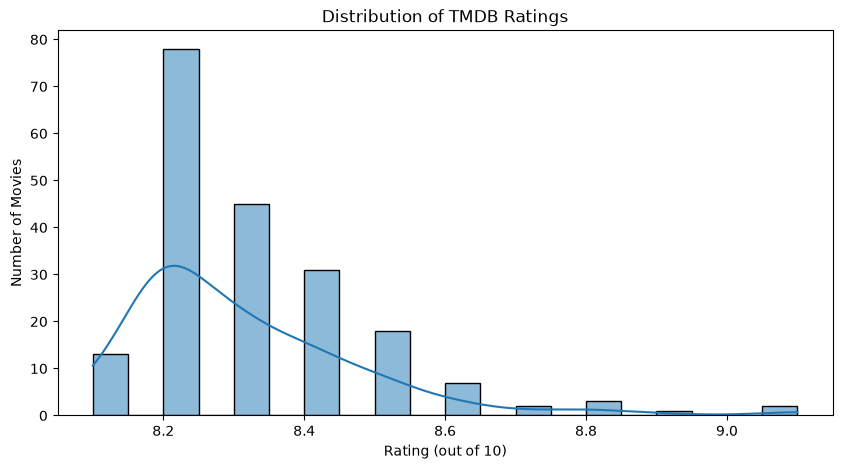

In [61]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Rating",
    bins=20,
    kde=True
)

plt.title("Distribution of TMDB Ratings")
plt.xlabel("Rating (out of 10)")
plt.ylabel("Number of Movies")
plt.show()

### 2. Movies per Decade — Univariate Analysis

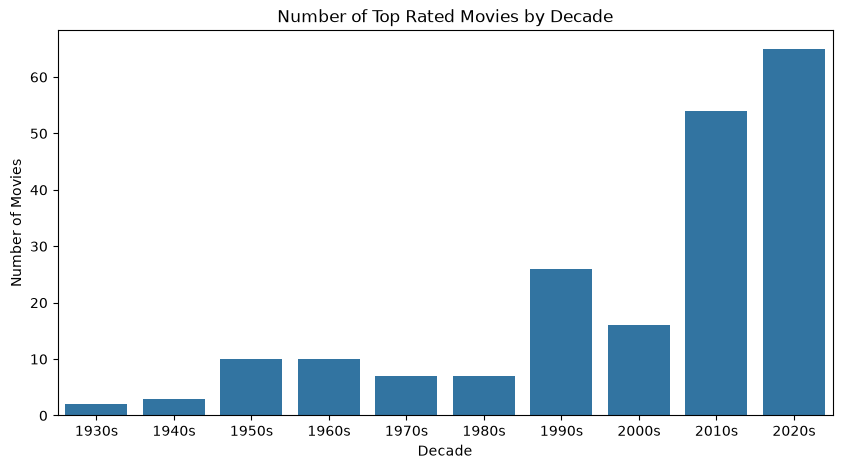

In [62]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Decade",
    order=sorted(df["Decade"].unique())
)

plt.title("Number of Top Rated Movies by Decade")
plt.xlabel("Decade")
plt.ylabel("Number of Movies")
plt.show()

### 3. Top 10 Genres — Univariate Analysis

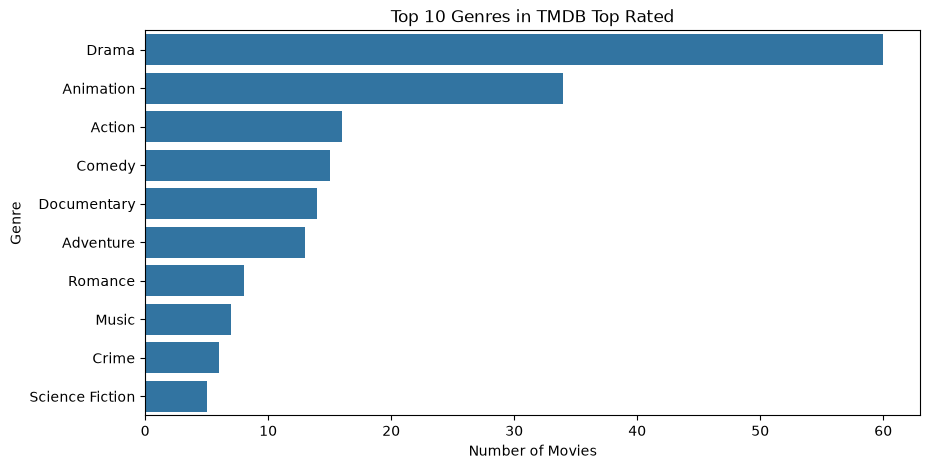

In [63]:
top_genres = df["Main_Genre"].value_counts().head(10)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=top_genres.values,
    y=top_genres.index
)

plt.title("Top 10 Genres in TMDB Top Rated")
plt.xlabel("Number of Movies")
plt.ylabel("Genre")
plt.show()

### 4. Runtime Distribution — Univariate Analysis

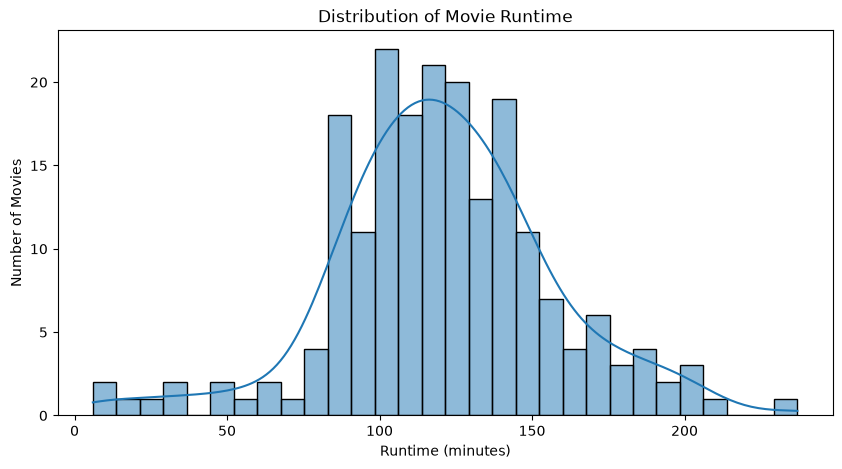

In [64]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Runtime",
    bins=30,
    kde=True
)

plt.title("Distribution of Movie Runtime")
plt.xlabel("Runtime (minutes)")
plt.ylabel("Number of Movies")
plt.show()

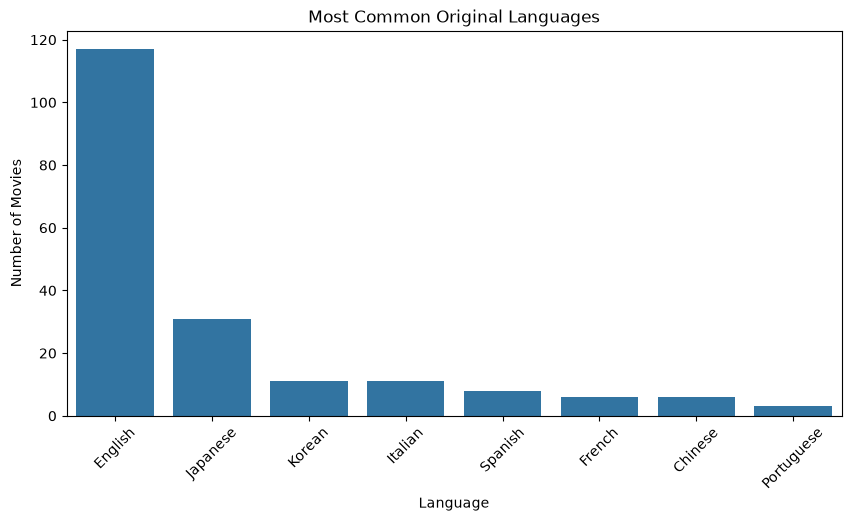

In [65]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Language",
    order=df["Language"].value_counts().head(8).index
)

plt.title("Most Common Original Languages")
plt.xlabel("Language")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45)
plt.show()

### 5. Decade Comparison — Bivariate Analysis

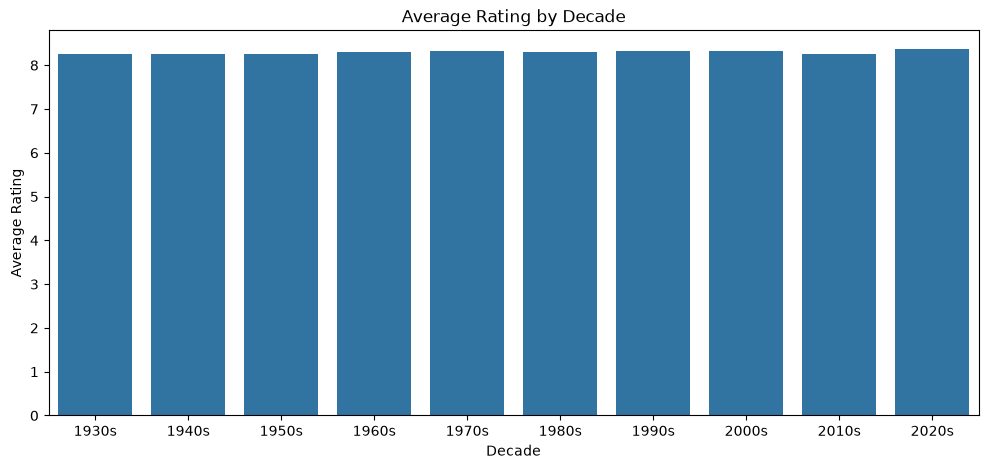

In [66]:
decade_rating = (
    df.groupby("Decade")["Rating"]
    .mean()
    .sort_index()
    .reset_index()
)

plt.figure(figsize=(12, 5))

sns.barplot(
    data=decade_rating,
    x="Decade",
    y="Rating"
)

plt.title("Average Rating by Decade")
plt.xlabel("Decade")
plt.ylabel("Average Rating")
plt.show()

### 6. Director Comparison — Bivariate Analysis

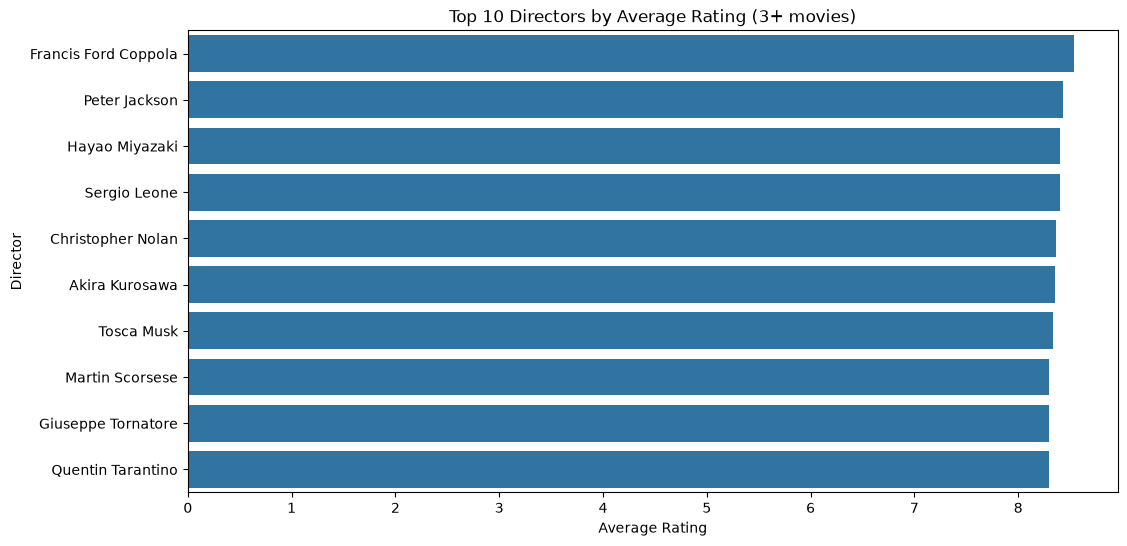

In [67]:
# only directors having at least 3 movies, so one lucky movie doesn't mislead
big_directors = df["Director"].value_counts()[lambda s: s >= 3].index

director_rating = (
    df[df["Director"].isin(big_directors) & (df["Director"] != "Unknown")]
    .groupby("Director")["Rating"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=director_rating,
    x="Rating",
    y="Director"
)

plt.title("Top 10 Directors by Average Rating (3+ movies)")
plt.xlabel("Average Rating")
plt.ylabel("Director")
plt.show()

### 7. Runtime vs Rating — Bivariate Analysis

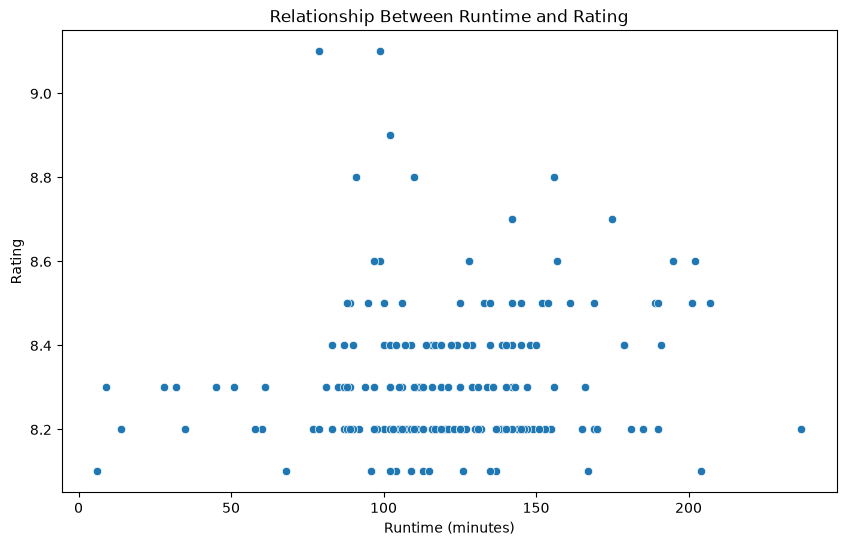

In [68]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Runtime",
    y="Rating"
)

plt.title("Relationship Between Runtime and Rating")
plt.xlabel("Runtime (minutes)")
plt.ylabel("Rating")
plt.show()

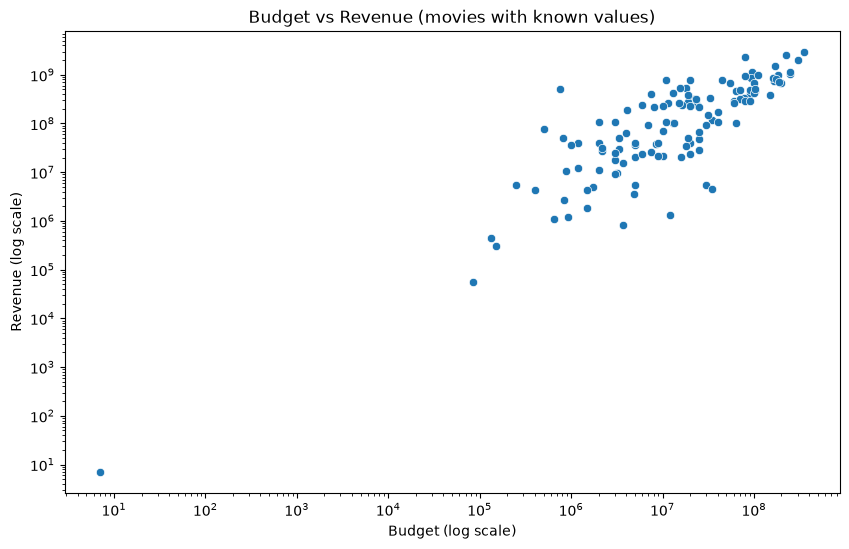

In [69]:
known = df[(df["Budget"] > 0) & (df["Revenue"] > 0)]

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=known,
    x="Budget",
    y="Revenue"
)

plt.xscale("log")
plt.yscale("log")
plt.title("Budget vs Revenue (movies with known values)")
plt.xlabel("Budget (log scale)")
plt.ylabel("Revenue (log scale)")
plt.show()

### 8. Correlation Heatmap — Multivariate Analysis

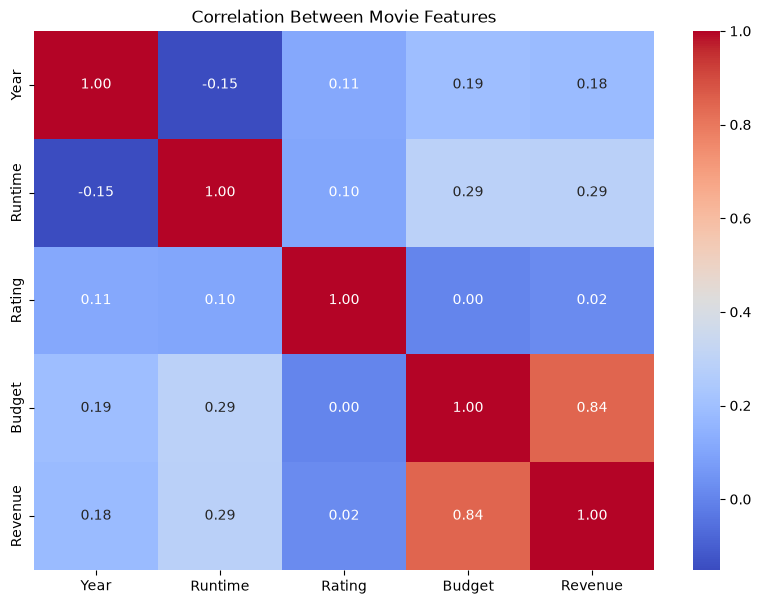

In [70]:
columns = [
    "Year",
    "Runtime",
    "Rating",
    "Budget",
    "Revenue"
]

correlation = df[columns].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Between Movie Features")
plt.show()

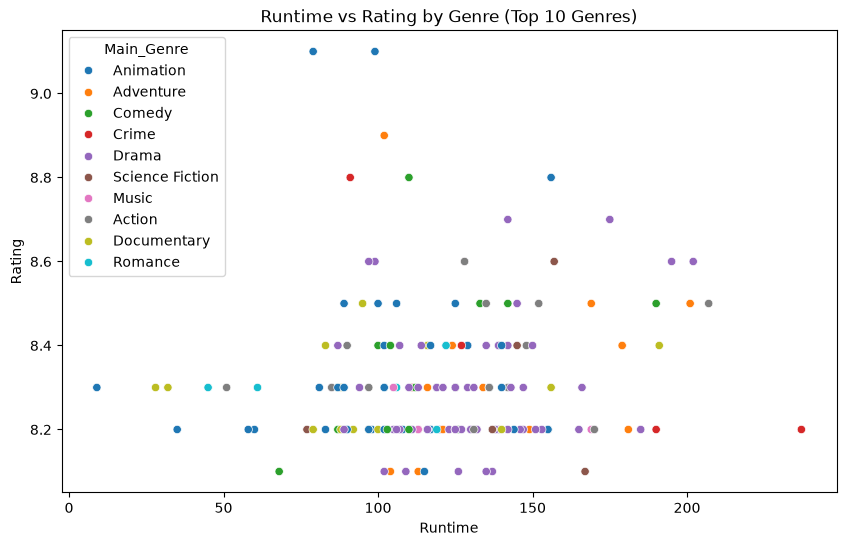

In [71]:
plt.figure(figsize=(10, 6))

sns.scatterplot(x="Runtime",
                y="Rating",
                hue="Main_Genre",
                data=df[df["Main_Genre"].isin(top_genres.index)])

plt.title("Runtime vs Rating by Genre (Top 10 Genres)")
plt.show()

### 9. Blockbuster Movie Analysis

In [72]:
blockbusters = df[df["Budget_Category"] == "Blockbuster"].copy()

blockbuster_genre = (
    blockbusters["Main_Genre"]
    .value_counts()
    .head(10)
)

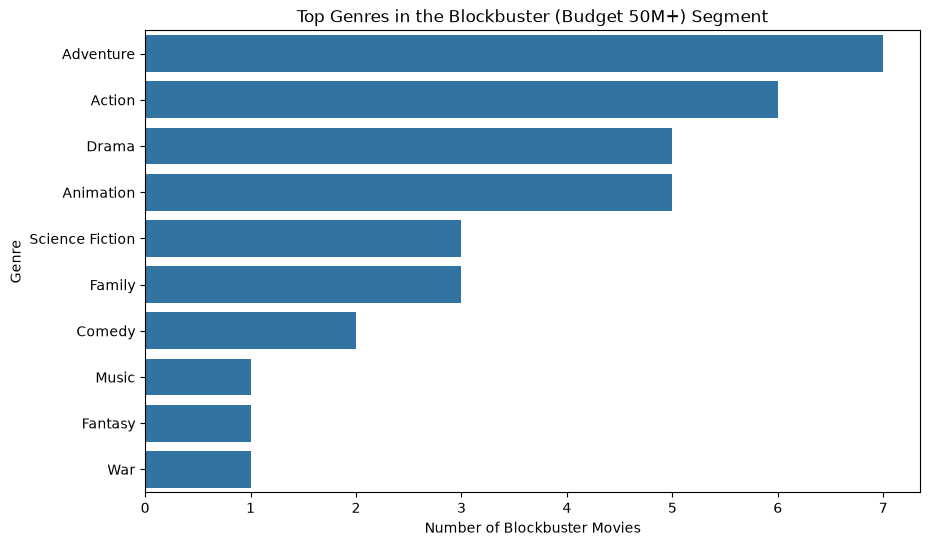

In [73]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=blockbuster_genre.values,
    y=blockbuster_genre.index
)

plt.title("Top Genres in the Blockbuster (Budget 50M+) Segment")
plt.xlabel("Number of Blockbuster Movies")
plt.ylabel("Genre")
plt.show()

In [74]:
df

,Rank,Title,Release_Date,Rating,Genre,Director,Runtime,Certificate,Language,Budget,Revenue,Overview,Link,Year,Rating_Category,Budget_Category,Decade,Main_Genre,Long_Movie,Profit
0,1,Batman: Knightfall Part 1: Knightfall,2026-06-23,9.1,"Animation, Action, Adventure, Drama",Jeff Wamester,79,R,English,0,0,"Arkham Asylum has been destroyed, and all its ...",https://www.themoviedb.org/movie/1560520-batma...,2026,Masterpiece,Unknown,2020s,Animation,No,NaN
1,2,Avatar Aang: The Last Airbender,2026-07-26,9.1,"Animation, Adventure, Fantasy, Action",Lauren Montgomery,99,PG,English,0,0,"Avatar Aang, the world's last Airbender, learn...",https://www.themoviedb.org/movie/980431-avatar...,2026,Masterpiece,Unknown,2020s,Animation,No,NaN
2,3,Swapped,2026-05-01,8.9,"Adventure, Animation, Family, Fantasy",Nathan Greno,102,U/A 7+,English,7,7,"A small woodland creature and a majestic bird,...",https://www.themoviedb.org/movie/1007757-swapped,2026,Masterpiece,Low Budget,2020s,Adventure,No,0.0
3,4,Accidental Partners,2026-03-12,8.8,"Comedy, Romance",Ihtzi Hurtado,110,B,Spanish,0,0,Two women discover they were both scammed by t...,https://www.themoviedb.org/movie/1632181-socia...,2026,Masterpiece,Unknown,2020s,Comedy,No,NaN
4,5,Demon Slayer: Kimetsu no Yaiba Infinity Castle,2025-09-12,8.8,"Animation, Action, Fantasy",Haruo Sotozaki,156,U/A 13+,Japanese,20000000,793594078,The Demon Slayer Corps are drawn into the Infi...,https://www.themoviedb.org/movie/1311031,2025,Masterpiece,Mid Budget,2020s,Animation,Yes,773594078.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,196,Togo,2019-12-20,8.1,"Adventure, History, Drama",Ericson Core,113,PG,English,0,0,The untold true story set in the winter of 192...,https://www.themoviedb.org/movie/606856-togo,2019,Good,Unknown,2010s,Adventure,No,NaN
196,197,The Seventh Seal,1957-02-16,8.1,"Fantasy, Drama",Unknown,96,15,Swedish,150000,311212,When disillusioned Swedish knight Antonius Blo...,https://www.themoviedb.org/movie/490-det-sjund...,1957,Good,Low Budget,1950s,Fantasy,No,161212.0
197,198,Better Days,2019-10-25,8.1,"Drama, Crime, Romance",Derek Tsang Kwok-Cheung,135,NR,Chinese,0,225879065,A bullied teenage girl forms an unlikely frien...,https://www.themoviedb.org/movie/575813,2019,Good,Unknown,2010s,Drama,No,NaN
198,199,Maquia: When the Promised Flower Blooms,2018-02-24,8.1,"Animation, Drama, Fantasy",Mari Okada,115,G,Japanese,0,4345395,"Fleeing the war, the immortal Maquia, graced w...",https://www.themoviedb.org/movie/476292,2018,Good,Unknown,2010s,Animation,No,NaN


## Business questions

### Which movie holds the highest rating on TMDB Top Rated?

In [ ]:
df.sort_values("Rating", ascending = False).head(1)[["Title", "Year", "Rating"]]

### Which decade has the highest number of top-rated movies

In [ ]:
df['Decade'].value_counts().sort_values(ascending = False).head(1)

### Which decade has the highest average rating (at least 5 movies)

In [ ]:
decade_stats = df.groupby('Decade')['Rating'].agg(['mean', 'count'])
decade_stats = decade_stats[decade_stats['count'] >= 5]
print(decade_stats['mean'].idxmax(), 'has the highest average rating')

### Rating Overview: What is the average, median, minimum, and maximum rating?

In [ ]:
print(f"Minimum Rating : {df['Rating'].min()}")
print(f"Maximum Rating : {df['Rating'].max()}")
print(f"Average Rating : {round(df['Rating'].mean(), 2)}")
print(f"Median Rating : {df['Rating'].median()}")

### What is the average, shortest and longest movie runtime

In [ ]:
print(f"Shortest movie : {df.loc[df['Runtime'].idxmin(), 'Title']} ({df['Runtime'].min()} min)")
print(f"Longest movie : {df.loc[df['Runtime'].idxmax(), 'Title']} ({df['Runtime'].max()} min)")
print(f"Average runtime : {round(df['Runtime'].mean())} min")

### Which certificate is most common

In [ ]:
common_certificate = df['Certificate'].value_counts().sort_values(ascending = False).head(1)
print(common_certificate)

### Which genre has the highest number of movies

In [ ]:
df['Main_Genre'].value_counts().sort_values(ascending = False).head(1)

### Which original language is the most common (and how many are non-English)

In [ ]:
print(df['Language'].value_counts().head(3))
print("Non-English movies :", (df['Language'] != 'English').sum())

### Which director has the most movies in the list

In [ ]:
directors = df[df['Director'] != 'Unknown']['Director'].value_counts()
print(directors.head(5))

### How many movies are longer than 150 minutes

In [ ]:
common_long = df['Long_Movie'].value_counts()
long_movie = common_long.idxmax()
count = common_long.max()
print(long_movie, ':', count)

### Are longer movies (150+ min) rated higher than shorter movies?

In [ ]:
avg_long_ratings = df.groupby('Long_Movie')['Rating'].mean()
if avg_long_ratings["Yes"] > avg_long_ratings["No"]:
    print('YES! Longer movies are rated higher than shorter movies')
else:
    print("Shorter movies are rated higher than longer movies")

### Do bigger-budget movies receive better ratings?

In [ ]:
budget_rating = df[df["Budget_Category"] != "Unknown"].groupby("Budget_Category")['Rating'].mean()
print(budget_rating)
print(budget_rating.idxmax(), "movies receive the best rating")

### Which movie earned the highest revenue

In [ ]:
df.sort_values("Revenue", ascending = False).head(1)[["Title", "Budget", "Revenue"]]

### Which movie made the highest profit

In [ ]:
df.sort_values("Profit", ascending = False).head(1)[["Title", "Budget", "Revenue", "Profit"]]

### Which genres dominate the Masterpiece (top 15% rated) segment?

In [ ]:
genre_segments = df.groupby('Rating_Category')['Main_Genre'].value_counts()
print(genre_segments["Masterpiece"].idxmax(), "genre dominates the Masterpiece segment")